# Leave-one-condition-out cross-validation

For every condition $h$ the final structure is refitted on the other 21 conditions (warm started at the final fit;
the bounds are recomputed from the training conditions only, so nothing of $h$ leaks into the fold). The held-out
steady state is then predicted from its enzyme levels: the drains are a fixed fraction of the PTS flux (the training
mean of $b/v_\mathrm{PTS}$), and among the steady states the one closest to the training-mean cofactors is selected.
The reference is the training-mean predictor. Code: `src/uncertainty/loocv.py`.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from uncertainty import loocv
from model.parameters import LI_FLUX_KEYS

FINAL = os.path.join(OUT, "final")
CV = os.path.join(OUT, "loocv")

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

In [3]:
if RUN:
    loocv.run_loocv_analysis(FINAL, CV, params)
else:
    print("RUN is False: the LOOCV is loaded from", CV)

RUN is False: the LOOCV is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model/loocv


In [4]:
summary = json.load(open(os.path.join(CV, "loocv_summary.json")))
folds = pd.read_csv(os.path.join(CV, "fold_table.csv"))
for name in ("met_all_folds", "flux_li_all_folds"):
    scores = summary[name]
    print("%-18s RMSE %.3f (training-mean predictor %.3f), R2 against it %.3f" % (
        name, scores["rmse_model"], scores["rmse_baseline"], scores["r2_vs_baseline"]))
print("folds failed: %d; closure solves failed: %d" % (summary["n_folds_failed"], summary["n_closure_failed"]))
folds.round(4)

met_all_folds      RMSE 0.206 (training-mean predictor 0.166), R2 against it -0.539
flux_li_all_folds  RMSE 1.404 (training-mean predictor 0.762), R2 against it -2.399
folds failed: 0; closure solves failed: 3


,h,obj_fold,wall_s,closure_success,closure_status,closure_max_residual,error
0,KO02,11.4546,6.9784,True,Solve_Succeeded,0.0000,NaN
1,KO03,11.6718,6.8896,True,Solve_Succeeded,0.0000,NaN
2,KO04,12.2123,4.6443,True,Solve_Succeeded,0.0000,NaN
3,KO05,12.6490,4.8122,False,Solve_Succeeded,0.0001,NaN
4,KO07,11.4409,3.9237,True,Solve_Succeeded,0.0000,NaN
5,KO08,11.4332,5.2310,True,Solve_Succeeded,0.0000,NaN
6,KO10,11.4504,4.4014,True,Solve_Succeeded,0.0000,NaN
7,KO11,11.0715,4.9291,True,Solve_Succeeded,0.0000,NaN
8,KO12,11.4446,4.3549,True,Solve_Succeeded,0.0000,NaN
9,KO13,11.3232,5.7868,True,Solve_Succeeded,0.0000,NaN


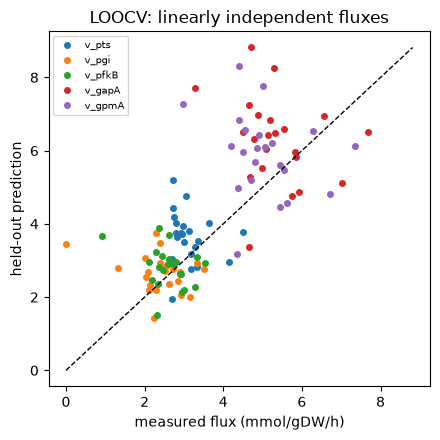

In [5]:
real = pd.read_csv(os.path.join(CV, "loocv_real.csv"), index_col=0)
predicted = pd.read_csv(os.path.join(CV, "loocv_pred.csv"), index_col=0)
flux_columns = [c for c in LI_FLUX_KEYS if real[c].notna().any()]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
for column in flux_columns:
    ax.plot(real[column], predicted[column], "o", ms=4, label=column)
limits = [min(np.nanmin(real[flux_columns].to_numpy()), np.nanmin(predicted[flux_columns].to_numpy())),
          max(np.nanmax(real[flux_columns].to_numpy()), np.nanmax(predicted[flux_columns].to_numpy()))]
ax.plot(limits, limits, "k--", lw=1)
ax.set_xlabel("measured flux (mmol/gDW/h)")
ax.set_ylabel("held-out prediction")
ax.legend(fontsize=7)
ax.set_title("LOOCV: linearly independent fluxes")
fig.tight_layout()
plt.show()